[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/philippe-amuzuga/Meca-IA_Ed2026/blob/main/meca-ia/C09/E09-1_Controle_Dimensionnel_CORRIGE.ipynb)

# Contrôle dimensionnel d'arbres usinés : choisir un seuil sur les courbes ROC et précision-rappel

## Le contexte

En fin de ligne, des arbres tournés puis rectifiés passent au contrôle. Le relevé donne, pour chaque pièce, l'écart de cote à la cote nominale, le défaut de circularité, la rugosité Ra et le déficit de dureté par rapport au minimum exigé, avec le poste de rectification et l'usure de l'outil au moment de l'usinage. Les trois postes rectifient trois séries : le plan fixe une tolérance pour chaque caractéristique, mais les séries n'ont pas toutes la même, et le fichier ne la donne pas. Une pièce est un rebut dès qu'une de ses caractéristiques sort de la tolérance de sa série. Les deux erreurs ne coûtent pas pareil : expédier un rebut déclenche un retour, un tri et un arrêt de ligne chez le client, alors qu'arrêter à tort une bonne pièce ne coûte que sa valeur. Le service qualité formule la règle ainsi : arrêter le plus possible de pièces défectueuses, sans que plus d'une pièce arrêtée sur dix soit saine.

Un modèle ne rend pas une décision, il rend une probabilité de rebut. La décision naît d'un seuil sur cette probabilité, et le seuil habituel de 0,5 n'est un bon choix que si les deux erreurs coûtent autant.

Défi : prédire `etat_piece` et obtenir un rappel des rebuts supérieur à celui du modèle de départ sur la base de test, avec une précision des pièces arrêtées d'au moins 0,90 : sous ce plancher, le score est nul. Le modèle de départ est une régression logistique qui ne regarde que l'écart de cote, au seuil de 0,5 ; il atteint un rappel de 0,576 : à vous d'ajouter les autres mesures et de choisir le seuil. La règle de découpage est fixée plus bas. La base de test sert à mesurer, jamais à apprendre ni à régler.

## Les données

Fichier `MecaIA-Controle_Dimensionnel.xlsx`, dans le dossier `donnees` du dépôt : 1 500 pièces, 7 colonnes. Une ligne est une pièce contrôlée en fin de ligne.

| Colonne | Signification | Unité |
|---|---|---|
| `poste` | poste de rectification : `A`, `B` ou `C` ; chaque poste rectifie une série à tolérance propre | catégorie |
| `usure_outil_pct` | usure de l'outil au moment de la pièce, en pourcentage de sa durée de vie | % |
| `ecart_cote_um` | écart de cote mesuré, en valeur absolue, par rapport à la cote nominale | µm |
| `circularite_um` | défaut de circularité mesuré | µm |
| `rugosite_Ra_um` | rugosité arithmétique Ra mesurée | µm |
| `deficit_durete_HRC` | déficit de dureté mesuré par rapport au minimum exigé, en valeur absolue | HRC |
| `etat_piece` | cible : `conforme` ou `rebut` | catégorie |

Origine : jeu simulé. Une pièce est rebutée dès qu'une caractéristique vraie dépasse la tolérance de sa série ; l'usure de l'outil dégrade les caractéristiques, l'instrument ajoute un petit bruit de mesure, et quelques rugosités ne sont pas relevées. Il enseigne une méthode, et aucune conclusion de contrôle n'en découle.

### Étape 1 : charger le fichier et regarder sa forme

On lit le classeur, puis on vérifie ses dimensions, ses cases vides et la répartition des deux états avant toute modélisation : la forme d'un fichier se lit sur le fichier entier. Le dossier des données est cherché depuis le dossier du notebook, puis depuis un clone du dépôt ; ouvert seul, par exemple dans Colab, le notebook télécharge une fois le jeu depuis le dépôt public.

In [1]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config

set_config(display="text")
GRAINE = 42
FICHIER = "MecaIA-Controle_Dimensionnel.xlsx"
URL_JEU = "https://raw.githubusercontent.com/philippe-amuzuga/Meca-IA_Ed2026/main/donnees/MecaIA-Controle_Dimensionnel.xlsx"

# Le dossier `donnees` du dépôt, cherché depuis le dossier du notebook, puis depuis un clone.
candidats = [Path("..", "..", "donnees"), Path("Meca-IA_Ed2026", "donnees")]
dossier = next((d for d in candidats if (d / FICHIER).is_file()), None)
if dossier is None:
    # Notebook ouvert seul (Colab) : copie unique du jeu depuis le dépôt public.
    dossier = Path("donnees")
    dossier.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_JEU, dossier / FICHIER)
    except OSError as erreur:
        raise FileNotFoundError(
            "Jeu introuvable : clonez le dépôt, ou vérifiez la connexion pour le télécharger.") from erreur
df = pd.read_excel(dossier / FICHIER)

cible = "etat_piece"
categories = ["poste"]
mesures = ["usure_outil_pct", "ecart_cote_um", "circularite_um", "rugosite_Ra_um", "deficit_durete_HRC"]
print("dimensions :", df.shape)
vides = df.isna().sum()
print("cases vides :", vides[vides > 0].to_dict())
print(df[cible].value_counts().to_dict())
df.head(3)

dimensions : (1500, 7)
cases vides : {'rugosite_Ra_um': 44}
{'conforme': 1237, 'rebut': 263}


,poste,usure_outil_pct,ecart_cote_um,circularite_um,rugosite_Ra_um,deficit_durete_HRC,etat_piece
0,A,34,1.6,1.3,0.52,0.9,conforme
1,B,53,2.0,3.0,0.74,0.9,conforme
2,B,87,6.8,4.4,0.73,0.7,rebut


Lecture du résultat : 1 500 pièces, 7 colonnes. La rugosité compte 44 cases vides, qu'il faudra remplir. 263 pièces sont des rebuts, soit 17,5 % : la classe à retrouver est minoritaire, et un modèle qui déclarerait toutes les pièces conformes aurait quand même une exactitude de 82,5 %.

### Préparation du dépôt (Colab)

Ouvert seul dans Colab, ce notebook ne voit pas le dossier `donnees/` du dépôt. La cellule suivante ne télécharge rien : elle cherche ce dossier (à deux dossiers au-dessus du notebook, à côté de lui ou dans un clone nommé `Meca-IA_Ed2026`), vérifie la présence du classeur du défi et, sur Colab, liste ce qui manque. Pour le fournir, ouvrez le panneau des fichiers de Colab, créez le dossier `donnees` à la racine de l'espace de travail et téléversez-y le classeur listé, pris dans le dépôt.

In [ ]:
# Préparation du dépôt (utile sur Colab) : cette cellule ne télécharge rien.
import os
from pathlib import Path

JEUX_LUS = ["MecaIA-Controle_Dimensionnel.xlsx"]                  # le classeur lu par ce notebook


def chercher(dossier):
    """Le dossier du dépôt cherché depuis le notebook, puis depuis un clone ; None s'il est introuvable."""
    for base in (Path("..", ".."), Path("."), Path("Meca-IA_Ed2026")):
        if (base / dossier).is_dir():
            return base / dossier
    return None


donnees = chercher("donnees")
manque = [f"donnees/{nom}" for nom in JEUX_LUS if donnees is None or not (donnees / nom).is_file()]
if manque and "COLAB_RELEASE_TAG" in os.environ:          # variable posée par Colab
    print("À téléverser dans l'espace de travail de Colab, panneau des fichiers :")
    print("\n".join("  " + nom for nom in manque))


### Étape 2 : mettre le test de côté

Un quart des pièces est mis de côté avant tout apprentissage, tout réglage et toute comparaison avec la cible. La graine 42 fixe le tirage : chacun obtient la même base de test, et les scores se comparent. Le tirage est stratifié, pour que les deux états soient représentés dans les deux bases dans la même proportion. Le rebut devient la classe positive, `1`.

In [2]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=cible)
y = (df[cible] == "rebut").astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=GRAINE, stratify=y)
print("apprentissage :", len(X_train), "pièces, dont", int(y_train.sum()), "rebuts")
print("test :", len(X_test), "pièces, dont", int(y_test.sum()), "rebuts")

apprentissage : 1125 pièces, dont 197 rebuts
test : 375 pièces, dont 66 rebuts


### Étape 3 : définir le score

Le score du défi est le rappel des rebuts : la part des pièces défectueuses qui sont arrêtées. Il serait trop facile de l'obtenir en arrêtant toutes les pièces, d'où le plancher de précision, qui est la part de vraies pièces défectueuses parmi les pièces arrêtées : sous 0,90, le score est nul. Trois témoins sans apprentissage montrent pourquoi : tout accepter, tout arrêter, et la règle que le service applique sans modèle, arrêter toute pièce dont une mesure dépasse la tolérance du plan.

In [3]:
from sklearn.metrics import precision_score, recall_score

PRECISION_MINIMALE = 0.90
TOLERANCES_PLAN = {"ecart_cote_um": 5.0, "circularite_um": 6.0, "rugosite_Ra_um": 1.8, "deficit_durete_HRC": 3.5}


def score_defi(y_vrai, y_predit):
    """Rappel des rebuts, ramené à zéro si la précision des pièces arrêtées tombe sous le plancher."""
    if precision_score(y_vrai, y_predit, zero_division=0) < PRECISION_MINIMALE:
        return 0.0
    return recall_score(y_vrai, y_predit)


def regle_du_plan(pieces):
    """Arrête toute pièce dont une mesure dépasse la tolérance du plan ; une case vide ne déclenche rien."""
    depassements = [pieces[colonne] > tolerance for colonne, tolerance in TOLERANCES_PLAN.items()]
    return np.any(depassements, axis=0).astype(int)


temoins = {"tout accepter": np.zeros(len(y_test), dtype=int),
           "tout arrêter": np.ones(len(y_test), dtype=int),
           "règle du plan": regle_du_plan(X_test)}
for nom, decision in temoins.items():
    print(f"{nom} : rappel {recall_score(y_test, decision):.3f}, "
          f"précision {precision_score(y_test, decision, zero_division=0):.3f}, score {score_defi(y_test, decision):.3f}")

tout accepter : rappel 0.000, précision 0.000, score 0.000
tout arrêter : rappel 1.000, précision 0.176, score 0.000
règle du plan : rappel 0.591, précision 0.975, score 0.591


Lecture du résultat : tout accepter ne retrouve aucun rebut. Tout arrêter retrouve tous les rebuts, avec un rappel de 1,000, mais sa précision n'est que de 0,176 : 82 % des pièces arrêtées sont saines, le plancher n'est pas tenu et le score est nul. La règle du plan, elle, ne se trompe presque jamais quand elle arrête une pièce (précision 0,975), mais elle laisse passer 41 % des rebuts (rappel 0,591) : la tolérance du plan n'est pas celle que chaque série applique. Un bon modèle doit retrouver beaucoup de rebuts en gardant les pièces saines hors du lot arrêté.

### Étape 4 : construire le modèle de départ

Le modèle de départ est une régression logistique, qui estime la probabilité de rebut de chaque pièce, puis arrête toute pièce dont la probabilité dépasse 0,5. Il ne regarde qu'une seule mesure, l'écart de cote, mise à l'échelle sur l'apprentissage seul dans le même pipeline. Il apprend sur la colonne `ecart_cote_um` de `X_train`.

In [4]:
# Solution :
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

modele = make_pipeline(StandardScaler(), LogisticRegression())
modele.fit(X_train[["ecart_cote_um"]], y_train)
# Fin de la solution

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression())])

### Étape 5 : mesurer sur la base de test

Le modèle prédit les pièces qu'il n'a jamais vues, avec le seuil de 0,5. On lit le score du défi, la précision, et la matrice de confusion : combien de rebuts arrêtés, combien laissés passer, combien de pièces saines arrêtées à tort.

In [5]:
from sklearn.metrics import confusion_matrix

y_pred = modele.predict(X_test[["ecart_cote_um"]])
score_depart = score_defi(y_test, y_pred)
precision_depart = precision_score(y_test, y_pred)
vrais_negatifs, fausses_alertes, rebuts_manques, rebuts_arretes = confusion_matrix(y_test, y_pred).ravel()
print(f"rappel des rebuts (score) : {score_depart:.3f}")
print(f"précision des pièces arrêtées : {precision_depart:.3f} (plancher {PRECISION_MINIMALE})")
print(f"rebuts arrêtés : {rebuts_arretes}, rebuts laissés passer : {rebuts_manques}, pièces saines arrêtées : {fausses_alertes}")

rappel des rebuts (score) : 0.576
précision des pièces arrêtées : 0.905 (plancher 0.9)
rebuts arrêtés : 38, rebuts laissés passer : 28, pièces saines arrêtées : 4


Lecture du résultat : le rappel est de 0,576 : 38 rebuts arrêtés sur 66, et 28 laissés passer. La précision est de 0,905, au-dessus du plancher de 0,90 : 4 pièces saines sont arrêtées à tort. Une partie des rebuts n'est donc pas vue, et il y a de la marge pour retrouver les autres, avec les autres mesures et un seuil choisi par la règle. C'est ce chiffre, mesuré sur des pièces que le modèle n'a jamais vues, que l'on a le droit d'annoncer.

## Pour aller plus loin : les courbes, puis un seuil fixé par la règle métier

Le modèle de départ de l'étape 4 reste le score de référence du défi. Les quatre cellules suivantes montrent comment le dépasser sans regarder le test pour choisir. La première obtient des probabilités hors échantillon sur l'apprentissage, par validation croisée, pour le modèle de départ et pour trois modèles qui voient toutes les mesures et le poste. La deuxième trace leurs courbes ROC et précision-rappel : ces courbes disent le classement des pièces, pas encore la décision. La troisième retient le modèle de plus grande précision moyenne, puis fixe son seuil sur ses probabilités d'apprentissage : le seuil qui retrouve le plus de rebuts en gardant la précision au moins égale à une valeur visée, un peu au-dessus du plancher pour garder de la marge sur des pièces nouvelles. La quatrième mesure ce modèle, avec ce seuil, une seule fois sur le test. Les valeurs sont lues dans les sorties imprimées.

In [6]:
# Solution :
from sklearn.compose import make_column_transformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import OneHotEncoder

preprocessor = make_column_transformer(
    (OneHotEncoder(), categories),
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), mesures))
plis = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
candidats = {
    "logistique sur toutes les mesures": make_pipeline(preprocessor, LogisticRegression(max_iter=1000)),
    "forêt aléatoire": make_pipeline(preprocessor, RandomForestClassifier(n_estimators=300, random_state=GRAINE)),
    "gradient boosting par histogrammes": make_pipeline(preprocessor, HistGradientBoostingClassifier(random_state=GRAINE))}
probas_cv = {"départ (écart de cote seul)": cross_val_predict(
    modele, X_train[["ecart_cote_um"]], y_train, cv=plis, method="predict_proba")[:, 1]}
for nom, pipeline in candidats.items():
    probas_cv[nom] = cross_val_predict(pipeline, X_train, y_train, cv=plis, method="predict_proba")[:, 1]
precision_moyenne = {nom: average_precision_score(y_train, proba) for nom, proba in probas_cv.items()}
for nom, proba in probas_cv.items():
    arrete = proba >= 0.5
    print(f"{nom} : ROC {roc_auc_score(y_train, proba):.4f}, précision moyenne {precision_moyenne[nom]:.4f} ; "
          f"au seuil de 0,5, rappel {recall_score(y_train, arrete):.3f}, précision {precision_score(y_train, arrete):.3f}")
# Fin de la solution

départ (écart de cote seul) : ROC 0.7896, précision moyenne 0.6709 ; au seuil de 0,5, rappel 0.472, précision 0.894
logistique sur toutes les mesures : ROC 0.9648, précision moyenne 0.8777 ; au seuil de 0,5, rappel 0.701, précision 0.831
forêt aléatoire : ROC 0.9953, précision moyenne 0.9812 ; au seuil de 0,5, rappel 0.919, précision 0.948
gradient boosting par histogrammes : ROC 0.9917, précision moyenne 0.9630 ; au seuil de 0,5, rappel 0.858, précision 0.914


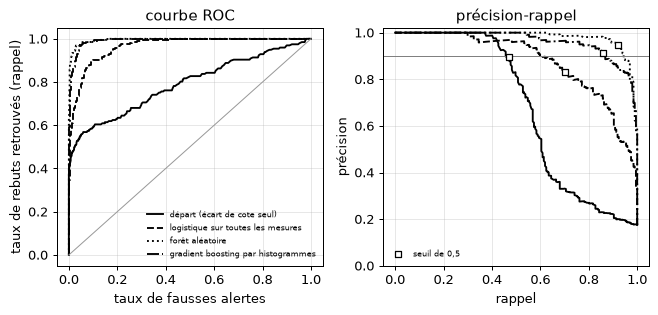

In [7]:
# Solution :
from sklearn.metrics import precision_recall_curve, roc_curve

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(7.4, 3.6))
for (nom, proba), trait in zip(probas_cv.items(), ["-", "--", ":", "-."]):
    fpr, tpr, _ = roc_curve(y_train, proba)
    precisions, rappels, _ = precision_recall_curve(y_train, proba)
    arrete = proba >= 0.5
    ax_roc.plot(fpr, tpr, trait, color="black", label=nom)
    ax_pr.plot(rappels, precisions, trait, color="black")
    ax_pr.scatter(recall_score(y_train, arrete), precision_score(y_train, arrete), marker="s", s=28,
                  color="white", edgecolor="black", zorder=3, label="seuil de 0,5" if trait == "-" else None)
ax_roc.plot([0, 1], [0, 1], color="0.6", linewidth=0.8)
ax_pr.axhline(PRECISION_MINIMALE, color="0.5", linewidth=0.8)
ax_roc.set(xlabel="taux de fausses alertes", ylabel="taux de rebuts retrouvés (rappel)", title="courbe ROC")
ax_pr.set(xlabel="rappel", ylabel="précision", ylim=(0, 1.02), title="précision-rappel")
ax_roc.legend(frameon=False, fontsize=6.5, loc="lower right")
ax_pr.legend(frameon=False, fontsize=6.5, loc="lower left")
for ax in (ax_roc, ax_pr):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
# Fin de la solution

In [8]:
PRECISION_VISEE = 0.95

# Solution :
nom_retenu = max(candidats, key=precision_moyenne.get)
print("modèle retenu par la précision moyenne :", nom_retenu)

precisions, rappels, seuils = precision_recall_curve(y_train, probas_cv[nom_retenu])
admis = precisions[:-1] >= PRECISION_VISEE
seuil = seuils[admis][np.argmax(rappels[:-1][admis])]
pred_cv = (probas_cv[nom_retenu] >= seuil).astype(int)
print(f"seuil retenu pour une précision visée de {PRECISION_VISEE} : {seuil:.3f}")
print(f"à ce seuil, en validation croisée : rappel {recall_score(y_train, pred_cv):.3f}, "
      f"précision {precision_score(y_train, pred_cv):.3f}")
# Fin de la solution

modèle retenu par la précision moyenne : forêt aléatoire
seuil retenu pour une précision visée de 0.95 : 0.517
à ce seuil, en validation croisée : rappel 0.914, précision 0.952


In [9]:
# Solution :
retenu = candidats[nom_retenu].fit(X_train, y_train)
y_retenu = (retenu.predict_proba(X_test)[:, 1] >= seuil).astype(int)
print(f"{nom_retenu}, au seuil {seuil:.3f}, mesuré une fois sur le test : score {score_defi(y_test, y_retenu):.3f}")
print(f"rappel {recall_score(y_test, y_retenu):.3f}, précision {precision_score(y_test, y_retenu):.3f}")
print(f"gain sur le modèle de départ : {score_defi(y_test, y_retenu) - score_depart:+.3f}")
print(f"gain sur la règle du plan : {score_defi(y_test, y_retenu) - score_defi(y_test, temoins['règle du plan']):+.3f}")
# Fin de la solution

forêt aléatoire, au seuil 0.517, mesuré une fois sur le test : score 0.879
rappel 0.879, précision 0.935
gain sur le modèle de départ : +0.303
gain sur la règle du plan : +0.288


Lecture du résultat : le modèle retenu, forêt aléatoire, arrête 0,879 des rebuts avec une précision de 0,935. Il dépasse le modèle de départ et la règle du plan : les trois séries n'appliquent pas la même tolérance, et un modèle qui voit le poste et les mesures en même temps peut apprendre une limite propre à chaque poste, alors que la règle du plan n'en connaît qu'une. Le gain est mesuré sur 66 rebuts : un rebut de plus ou de moins déplace le rappel de 0,015.

## Le score de référence

Le score publié est le rappel des rebuts du modèle de départ de l'étape 4, au seuil de 0,5, sur la base de test. L'empreinte identifie cette base de test : si la vôtre diffère, le découpage n'est pas le même et les scores ne se comparent pas.

In [10]:
import hashlib

score = score_defi(y_test, modele.predict(X_test[["ecart_cote_um"]]))
positions = ",".join(str(i) for i in sorted(X_test.index))
print("EMPREINTE_TEST =", hashlib.sha256(positions.encode("ascii")).hexdigest())
print("SCORE_REFERENCE rappel = %.3f" % score)

EMPREINTE_TEST = fb3f83ef6a78501f0dc724be56345bbfc67b7edd794407f06fa7fe577a1944fb
SCORE_REFERENCE rappel = 0.576


## Synthèse

1. Un modèle rend une probabilité ; la décision vient d'un seuil, et le seuil de 0,5 ne vaut que si les deux erreurs ont le même coût.
2. La courbe ROC dit comment le classement des pièces sépare les deux états quel que soit le seuil ; la courbe précision-rappel dit ce que chaque seuil coûte en pièces saines arrêtées.
3. Un score qui n'a qu'un côté, comme le rappel, se triche en arrêtant tout : une règle métier, ici un plancher de précision, le rend honnête, et les témoins sans apprentissage le montrent. La règle du plan, qui n'apprend rien, laisse passer une partie des rebuts : les séries n'ont pas la même tolérance, et c'est ce que l'apprentissage retrouve dans les données.
4. Une seule mesure ne voit qu'une partie des rebuts : en validation croisée, la précision moyenne passe de 0,671 pour l'écart de cote seul à 0,981 pour le modèle retenu, qui voit toutes les mesures et le poste.
5. Le seuil par défaut ne tient pas la règle pour tous les modèles : au seuil de 0,5, la précision en validation croisée tombe sous le plancher de 0,90 pour 1 des 3 modèles qui voient toutes les mesures, « logistique sur toutes les mesures » (0,831). Le seuil se fixe donc sur des probabilités hors échantillon de l'apprentissage, avec la règle métier et une marge de sécurité ; il ne se règle jamais sur le test.
6. Le test ne sert qu'une fois, au modèle retenu et à son seuil : avec 66 rebuts dans la base de test, un rebut de plus ou de moins retrouvé déplace le rappel de 0,015.